# Shortest Path — A* on Road Network
Computes and visualizes the shortest path between two points along segmented roads using A* with Euclidean heuristic.

In [1]:
# Necessary imports
import heapq
import matplotlib.pyplot as plt
import numpy as np
import cv2

## A* Pathfinding Pipeline

1. **Grid Construction** — Segmented road mask morphologically cleaned and converted to binary grid
2. **Coordinate Scaling** — User-defined coordinates scaled to match downsampled grid       
[snapped to nearest road pixel if not exactly on road]
3. **A* Search** — Explores road pixels using f = g + h where g is actual cost and h is Euclidean distance to goal  
[supports 8-directional movement with diagonal corner-cutting prevention]
4. **Visualization** — Path overlaid on both segmented mask and original topdown image

**Note:** Coordinates are specified in original image space and automatically mapped to the grid. Intended implementation would accept coordinates from original fragmented images and trace them through cumulative homographies to the final stitched map — not completed due to time constraints.

In [2]:
# Specify start and end coordinates for path finding
start = (100,200)
end = (800,1500)

In [3]:
# Resize Grid to specified scale
scale = 0.5
def resize_grid(grid):
    h, w = grid.shape
    new_size = (int(w*scale), int(h*scale))
    small = cv2.resize(grid, new_size, interpolation=cv2.INTER_NEAREST)
    return small

In [4]:
# Read segmented image, morph and convert it to a grid
mask = cv2.imread("segmented_mask.png", cv2.IMREAD_GRAYSCALE)

if mask is None:
    print("Error: segmented_mask.png not found. Run the segmentation pipeline first.")
    exit()

kernel = np.ones((5,5), np.uint8)
mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

grid = (mask != 255).astype(np.uint8)  # 0 = road, 1 = obstacle
grid = resize_grid(grid)

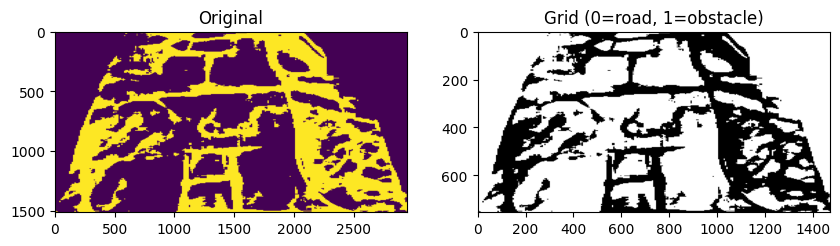

In [5]:
# Display segmented image and extracted grid
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(mask)
plt.title("Original")

plt.subplot(1,2,2)
plt.imshow(grid, cmap='gray')
plt.title("Grid (0=road, 1=obstacle)")
plt.show()

In [ ]:
class Node:
    # constructor to initialize all values
    def __init__(self, x, y, g=0, h=0, parent=None):
        self.x = x
        self.y = y
        self.g = g
        self.h = h
        self.f = g + h
        self.parent = parent

    # Comparison for heapq priority queue ordering by f cost
    def __lt__(self, other):
        return self.f < other.f  

In [7]:
# Calculate Euclidean distance
def heuristic(x1, y1, x2, y2):
    return ((x1 - x2)**2 + (y1 - y2)**2) ** 0.5  

In [8]:
# Check whether node is within boundary and not an obstacle
def is_walkable(x, y):
    return (0 <= x < grid.shape[0] and 
            0 <= y < grid.shape[1] and 
            grid[x][y] == 0)

In [9]:
# Reverse Path from goal -> start to start -> goal
def reconstruct_path(node):
    path = []
    while node:
        path.append((node.x, node.y))
        node = node.parent
    return path[::-1]

In [10]:
# Run the astar algorithm

def astar(start, end):
    open_heap = []
    heapq.heappush(open_heap, Node(start[0], start[1]))

    closed_set = set()
    visited = {}  # (x,y) -> g cost

    while open_heap:
        current = heapq.heappop(open_heap)

        if (current.x, current.y) == end:
            return reconstruct_path(current)

        closed_set.add((current.x, current.y))

        directions = [
            (0,1), (1,0), (0,-1), (-1,0),
            (1,1), (1,-1), (-1,1), (-1,-1)
        ]

        for dx, dy in directions:
            nx, ny = current.x + dx, current.y + dy

            if not is_walkable(nx, ny) or (nx, ny) in closed_set:
                continue

            # Prevent diagonal corner cutting
            if dx != 0 and dy != 0:
                if not (is_walkable(current.x + dx, current.y) and 
                        is_walkable(current.x, current.y + dy)):
                    continue

            if dx != 0 and dy != 0:
                new_g = current.g + 1.414  
            else:
                new_g = current.g + 1

            if (nx, ny) not in visited or new_g < visited[(nx, ny)]:
                visited[(nx, ny)] = new_g
                h = heuristic(nx, ny, end[0], end[1])
                neighbor = Node(nx, ny, new_g, h, current)
                heapq.heappush(open_heap, neighbor)

    return []  # no path

In [11]:
# If start or end point is not walkable snap to nearest obstacle-free point

def snap_to_road(point, grid):
    road_pixels = np.argwhere(grid == 0)  
    if len(road_pixels) == 0:
        return point
    distances = np.linalg.norm(road_pixels - np.array(point), axis=1)
    return tuple(road_pixels[np.argmin(distances)])

Snapped start: (np.int64(142), np.int64(219)), end: (np.int64(408), np.int64(750))
No path found


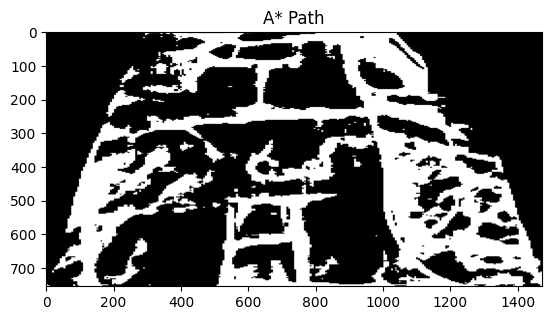

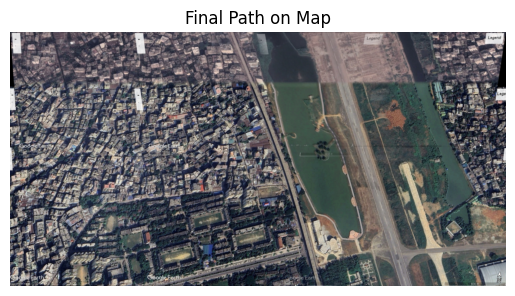

In [12]:
# Scale start and end coordinates
start_scaled = (int(start[0] * scale), int(start[1] * scale))
end_scaled = (int(end[0] * scale), int(end[1] * scale))

# Snap to nearest walkable points
START = snap_to_road(start_scaled, grid)
END = snap_to_road(end_scaled, grid)
print(f"Snapped start: {START}, end: {END}")

# Find, print and visualize path
if not is_walkable(*START):
    print("Start is not on a road")
elif not is_walkable(*END):
    print("End is not on a road")
else: 
    path = astar(START, END)
    path = [(int(x), int(y)) for x, y in path]

    if path:
        print("Path found:")
        print(path)
    else:
        print("No path found")

    # Path overlaid on segmented image/mask
    vis = cv2.cvtColor((1-grid)*255, cv2.COLOR_GRAY2BGR)

    for x, y in path:
        vis[x, y] = [255, 0, 0]  # red path

    plt.imshow(vis)
    plt.title("A* Path")
    plt.show()

    # Path overlaid on original image
    orig = cv2.imread("topdown_image.png")
    orig = cv2.resize(orig, (grid.shape[1], grid.shape[0]))

    for x, y in path:
        orig[x, y] = [0, 0, 255]

    plt.imshow(cv2.cvtColor(orig, cv2.COLOR_BGR2RGB))
    plt.title("Final Path on Map")
    plt.axis('off')
    plt.show()